In [ ]:
# Google Colab : télécharger les données de cette séance / download this session's data
import os, urllib.request
BASE = "https://raw.githubusercontent.com/Marzoug-Nabil/Nabil/main/academic/teaching/fsci6222/materials/s07/"
for f in ['expression_genique.csv', 'profil_clients.csv']:
    os.makedirs('data', exist_ok=True)
    for dst in (f, os.path.join('data', f)):
        if not os.path.exists(dst):
            urllib.request.urlretrieve(BASE + f, dst)


# FSCI 6222 — Analyse de données
## Séance 7 : PCA et t-SNE — Réduction de dimensionnalité

**Enseignant :** Nabil Marzoug  
**Date :** 2 juin 2026  
**Université de Moncton — Faculté des sciences**

---

### Objectifs de la séance
1. Comprendre le problème de la haute dimensionnalité (fléau de la dimension)
2. Comprendre le principe de l'ACP (Analyse en Composantes Principales / PCA)
3. Appliquer PCA avec scikit-learn et interpréter les résultats
4. Comprendre le principe de t-SNE et ses différences avec PCA
5. Visualiser des données en haute dimension en 2D

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

# Charger le dataset
df = pd.read_csv('profil_clients.csv')
print(f"Dimensions : {df.shape}")
df.head()

Dimensions : (50, 17)


,client_id,age,revenu_annuel,depenses_mensuelles,nb_achats_mois,anciennete_mois,score_credit,nb_produits,solde_compte,taux_utilisation_credit,nb_reclamations,satisfaction,nb_visites_web,nb_visites_magasin,montant_dernier_achat,jours_depuis_dernier_achat,segment
0,1,25,32000,1800,8,12,620,3,1500,0.75,1,3,15,2,120,5,Jeune actif
1,2,34,55000,3200,12,36,710,5,8500,0.45,0,4,10,5,350,3,Famille
2,3,45,72000,4100,15,60,780,7,25000,0.30,0,5,8,8,500,2,Premium
3,4,22,28000,1500,6,6,580,2,800,0.85,2,2,20,1,80,10,Jeune actif
4,5,56,85000,5500,18,96,820,8,45000,0.20,0,5,5,10,750,1,Premium


In [2]:
df.info()
print("\n")
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   client_id                   50 non-null     int64  
 1   age                         50 non-null     int64  
 2   revenu_annuel               50 non-null     int64  
 3   depenses_mensuelles         50 non-null     int64  
 4   nb_achats_mois              50 non-null     int64  
 5   anciennete_mois             50 non-null     int64  
 6   score_credit                50 non-null     int64  
 7   nb_produits                 50 non-null     int64  
 8   solde_compte                50 non-null     int64  
 9   taux_utilisation_credit     50 non-null     float64
 10  nb_reclamations             50 non-null     int64  
 11  satisfaction                50 non-null     int64  
 12  nb_visites_web              50 non-null     int64  
 13  nb_visites_magasin          50 non-null     int6

,client_id,age,revenu_annuel,depenses_mensuelles,nb_achats_mois,anciennete_mois,score_credit,nb_produits,solde_compte,taux_utilisation_credit,nb_reclamations,satisfaction,nb_visites_web,nb_visites_magasin,montant_dernier_achat,jours_depuis_dernier_achat
count,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00
mean,25.50,39.90,58770.00,3409.00,12.52,48.88,722.66,5.36,18762.00,0.45,0.48,3.90,10.08,6.02,377.10,3.82
std,14.58,12.69,20284.01,1233.53,3.78,34.27,79.13,2.17,18835.95,0.22,0.74,0.99,5.49,3.45,201.58,2.62
min,1.00,21.00,27000.00,1400.00,5.00,4.00,570.00,2.00,600.00,0.14,0.00,2.00,3.00,1.00,70.00,1.00
25%,13.25,30.00,40500.00,2325.00,9.25,22.50,661.25,3.25,3625.00,0.27,0.00,3.00,5.25,3.00,202.50,2.00
50%,25.50,37.50,56500.00,3325.00,12.00,39.00,716.50,5.00,9250.00,0.44,0.00,4.00,10.00,5.50,355.00,3.00
75%,37.75,48.75,75750.00,4375.00,16.00,69.00,793.75,7.00,31500.00,0.62,1.00,5.00,13.00,9.00,535.00,5.00
max,50.00,66.00,93000.00,5600.00,19.00,122.00,842.00,9.00,62000.00,0.88,3.00,5.00,24.00,12.00,750.00,12.00


---
# Partie 1 — Le problème de la haute dimensionnalité

## 1.1 Qu'est-ce que la dimensionnalité?

La **dimensionnalité** d'un dataset est le nombre de variables (colonnes) numériques.

Notre dataset a **14 variables numériques**. C'est impossible à visualiser en 2D ou 3D directement.

### Problèmes de la haute dimensionnalité :
- **Visualisation impossible** au-delà de 3 dimensions
- **Redondance** : plusieurs variables mesurent la même chose
- **Bruit** : certaines variables n'apportent pas d'information utile
- **Fléau de la dimension** (curse of dimensionality) : les algorithmes de ML perdent en performance avec trop de variables

In [3]:
# Sélectionner les variables numériques
cols_num = ['age', 'revenu_annuel', 'depenses_mensuelles', 'nb_achats_mois',
            'anciennete_mois', 'score_credit', 'nb_produits', 'solde_compte',
            'taux_utilisation_credit', 'nb_reclamations', 'satisfaction',
            'nb_visites_web', 'nb_visites_magasin', 'montant_dernier_achat']

print(f"Nombre de variables numériques : {len(cols_num)}")
print(f"Nombre d'observations : {len(df)}")

Nombre de variables numériques : 14
Nombre d'observations : 50


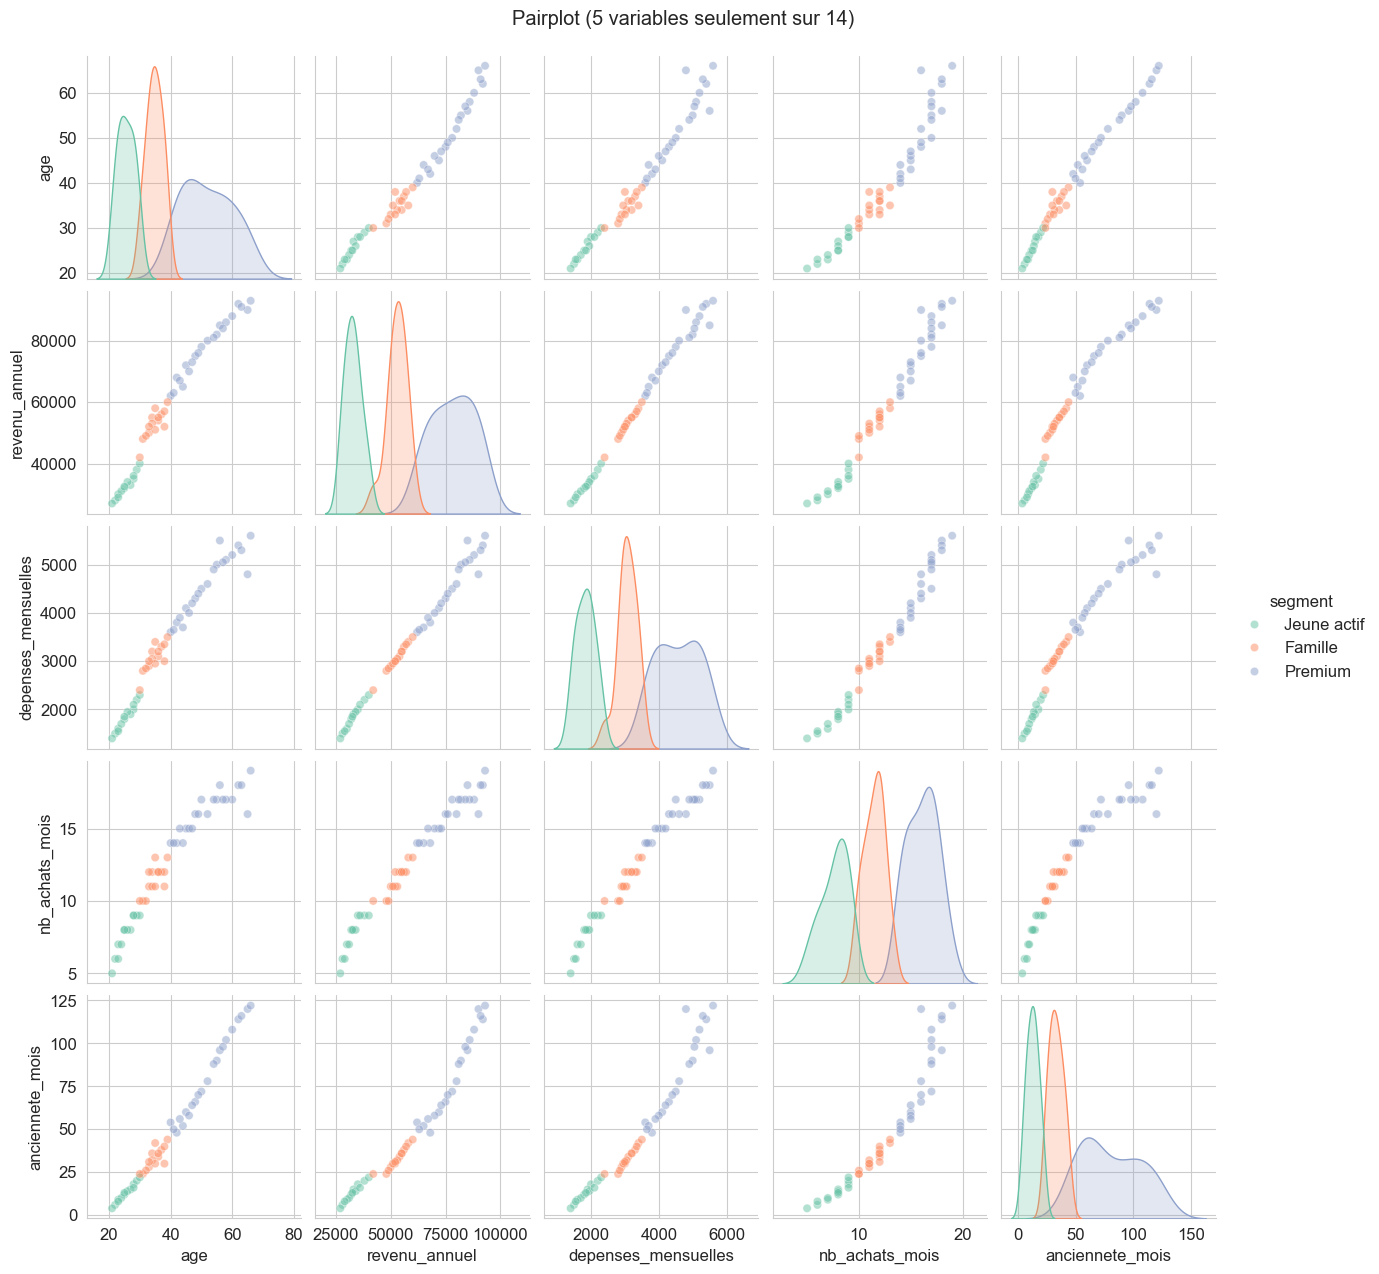

In [4]:
# Problème : on ne peut pas visualiser 14 dimensions d'un coup
# Le pairplot devient vite illisible
sns.pairplot(df[cols_num[:5] + ['segment']], hue='segment', 
             palette='Set2', diag_kind='kde', plot_kws={'alpha': 0.5})
plt.suptitle('Pairplot (5 variables seulement sur 14)', y=1.02)
plt.show()

## 1.2 La corrélation entre variables = redondance

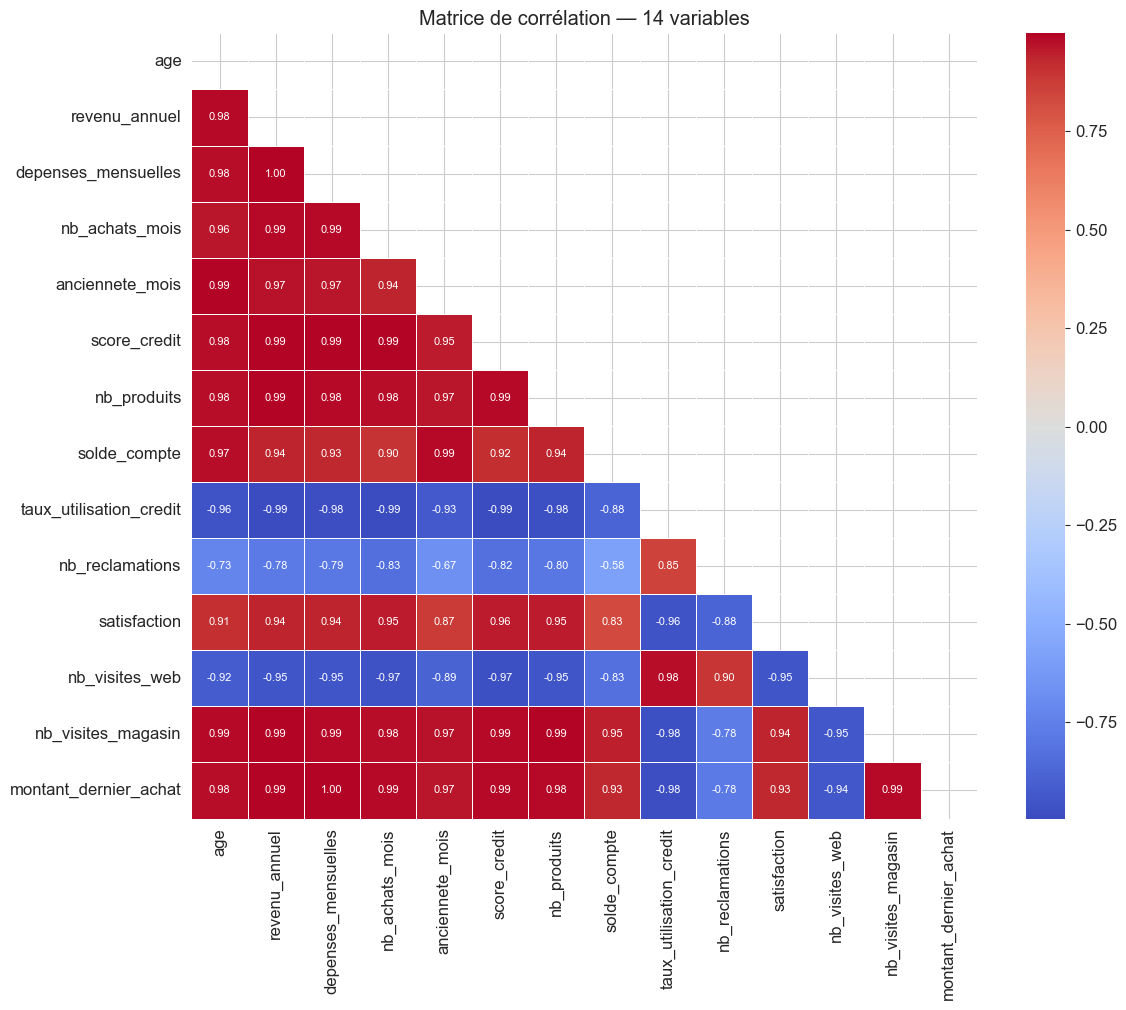

Paires avec |r| > 0.7 :
  age                            <-> revenu_annuel                  : r = +0.985
  age                            <-> depenses_mensuelles            : r = +0.979
  age                            <-> nb_achats_mois                 : r = +0.960
  age                            <-> anciennete_mois                : r = +0.992
  age                            <-> score_credit                   : r = +0.976
  age                            <-> nb_produits                    : r = +0.981
  age                            <-> solde_compte                   : r = +0.975
  age                            <-> taux_utilisation_credit        : r = -0.958
  age                            <-> nb_reclamations                : r = -0.725
  age                            <-> satisfaction                   : r = +0.909
  age                            <-> nb_visites_web                 : r = -0.921
  age                            <-> nb_visites_magasin             : r = +0.987
  ag

In [5]:
# Matrice de corrélation
corr = df[cols_num].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            mask=mask, square=True, linewidths=0.5, annot_kws={'size': 8})
plt.title('Matrice de corrélation — 14 variables')
plt.tight_layout()
plt.show()

# Identifier les paires très corrélées
print("Paires avec |r| > 0.7 :")
for i in range(len(cols_num)):
    for j in range(i+1, len(cols_num)):
        r = corr.iloc[i, j]
        if abs(r) > 0.7:
            print(f"  {cols_num[i]:30} <-> {cols_num[j]:30} : r = {r:+.3f}")

Beaucoup de variables sont corrélées entre elles → **redondance**. La PCA va résumer cette information.

---
# Partie 2 — PCA (Analyse en Composantes Principales)

## 2.1 Principe

La **PCA** (Principal Component Analysis) transforme les variables originales en un **nouveau système de coordonnées** appelé **composantes principales** (PC).

**Idée clé :**
- PC1 capture la **plus grande variance** possible dans les données
- PC2 capture la 2e plus grande variance, **perpendiculaire** à PC1
- PC3, PC4... capturent le reste
- On peut souvent garder seulement 2-3 composantes pour résumer l'essentiel de l'information

**Analogie :** Imaginez photographier un objet 3D. Une bonne photo (2D) capture l'essentiel de la forme. PCA trouve le meilleur "angle de vue" pour les données.

## 2.2 Étape préalable : Standardisation

**Obligatoire avant PCA !** Les variables doivent avoir la même échelle, sinon celles avec de grandes valeurs dominent les résultats.

In [6]:
# Avant standardisation : les échelles sont très différentes
print("Avant standardisation :")
print(f"  Revenu annuel  : min={df['revenu_annuel'].min():>10,}, max={df['revenu_annuel'].max():>10,}")
print(f"  Satisfaction   : min={df['satisfaction'].min():>10}, max={df['satisfaction'].max():>10}")
print(f"  Taux crédit    : min={df['taux_utilisation_credit'].min():>10.2f}, max={df['taux_utilisation_credit'].max():>10.2f}")

Avant standardisation :
  Revenu annuel  : min=    27,000, max=    93,000
  Satisfaction   : min=         2, max=         5
  Taux crédit    : min=      0.14, max=      0.88


In [7]:
# Standardisation : moyenne = 0, écart-type = 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cols_num])

# Vérifier
X_df = pd.DataFrame(X_scaled, columns=cols_num)
print("Après standardisation :")
print(X_df.describe().round(2).loc[['mean', 'std']])

Après standardisation :
       age  revenu_annuel  depenses_mensuelles  nb_achats_mois  \
mean  0.00          -0.00                -0.00            0.00   
std   1.01           1.01                 1.01            1.01   

      anciennete_mois  score_credit  nb_produits  solde_compte  \
mean            -0.00          0.00        -0.00         -0.00   
std              1.01          1.01         1.01          1.01   

      taux_utilisation_credit  nb_reclamations  satisfaction  nb_visites_web  \
mean                    -0.00             0.00          0.00            0.00   
std                      1.01             1.01          1.01            1.01   

      nb_visites_magasin  montant_dernier_achat  
mean                0.00                  -0.00  
std                 1.01                   1.01  


## 2.3 Appliquer PCA

In [8]:
# PCA avec toutes les composantes
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print(f"Dimensions originales : {X_scaled.shape}")
print(f"Dimensions après PCA  : {X_pca.shape}")
print(f"\nVariance expliquée par chaque composante :")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"  PC{i+1:2d} : {var:.4f} ({var*100:.1f}%)")

Dimensions originales : (50, 14)
Dimensions après PCA  : (50, 14)

Variance expliquée par chaque composante :
  PC 1 : 0.9419 (94.2%)
  PC 2 : 0.0434 (4.3%)
  PC 3 : 0.0046 (0.5%)
  PC 4 : 0.0040 (0.4%)
  PC 5 : 0.0023 (0.2%)
  PC 6 : 0.0012 (0.1%)
  PC 7 : 0.0008 (0.1%)
  PC 8 : 0.0007 (0.1%)
  PC 9 : 0.0004 (0.0%)
  PC10 : 0.0003 (0.0%)
  PC11 : 0.0002 (0.0%)
  PC12 : 0.0002 (0.0%)
  PC13 : 0.0001 (0.0%)
  PC14 : 0.0001 (0.0%)


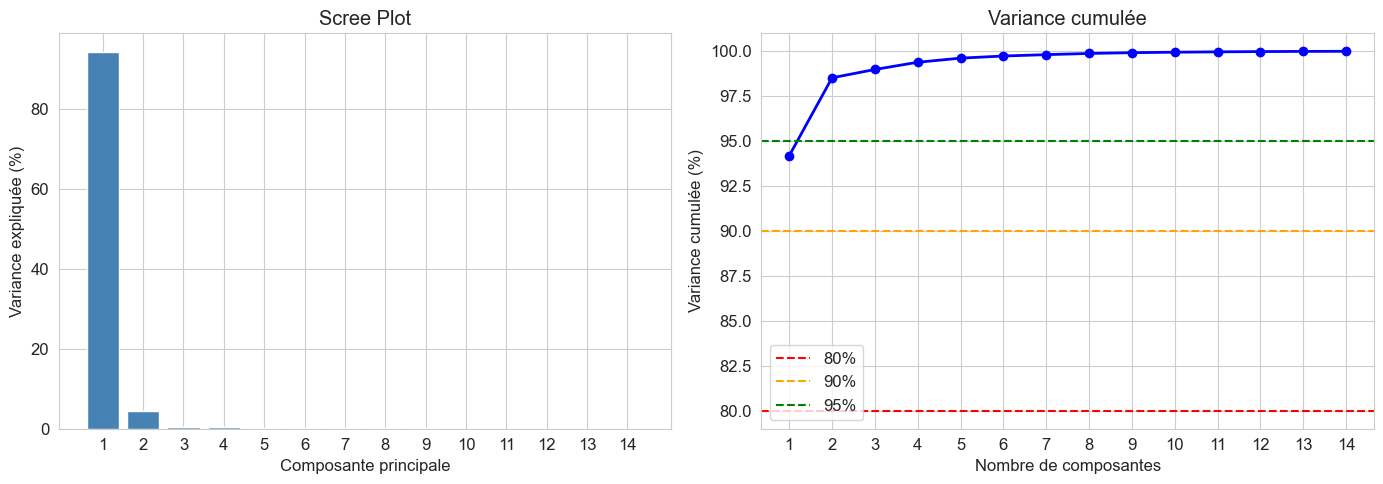

Composantes pour 90% de variance : 1
Composantes pour 95% de variance : 2

Réduction : 14 variables → 1 composantes (90%)


In [9]:
# Variance cumulée
cumul = np.cumsum(pca.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot (variance par composante)
axes[0].bar(range(1, len(pca.explained_variance_ratio_)+1), 
            pca.explained_variance_ratio_ * 100, 
            color='steelblue', edgecolor='white')
axes[0].set_xlabel('Composante principale')
axes[0].set_ylabel('Variance expliquée (%)')
axes[0].set_title('Scree Plot')
axes[0].set_xticks(range(1, len(pca.explained_variance_ratio_)+1))

# Variance cumulée
axes[1].plot(range(1, len(cumul)+1), cumul * 100, 'bo-', linewidth=2)
axes[1].axhline(y=80, color='red', linestyle='--', label='80%')
axes[1].axhline(y=90, color='orange', linestyle='--', label='90%')
axes[1].axhline(y=95, color='green', linestyle='--', label='95%')
axes[1].set_xlabel('Nombre de composantes')
axes[1].set_ylabel('Variance cumulée (%)')
axes[1].set_title('Variance cumulée')
axes[1].set_xticks(range(1, len(cumul)+1))
axes[1].legend()

plt.tight_layout()
plt.show()

# Combien de composantes pour 90% ?
n_90 = np.argmax(cumul >= 0.90) + 1
n_95 = np.argmax(cumul >= 0.95) + 1
print(f"Composantes pour 90% de variance : {n_90}")
print(f"Composantes pour 95% de variance : {n_95}")
print(f"\nRéduction : {len(cols_num)} variables → {n_90} composantes (90%)")

## 2.4 Visualisation en 2D

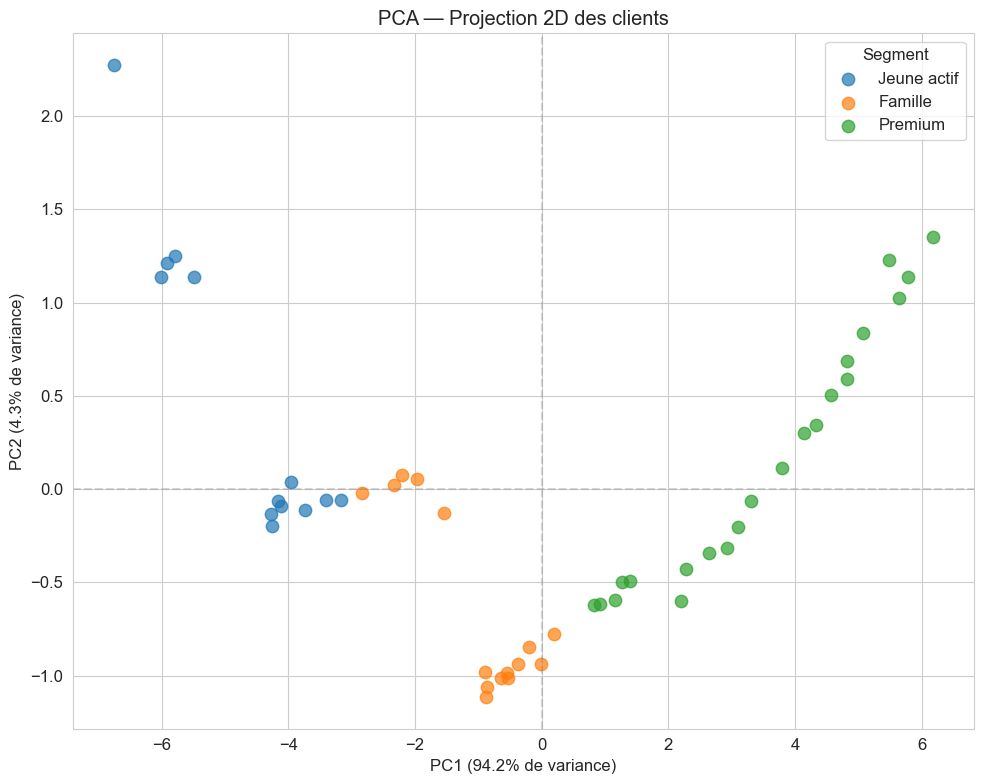


Variance expliquée (2 composantes) : 98.5%
On résume 14 variables en 2 dimensions!


In [12]:
# PCA avec 2 composantes pour la visualisation
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# Créer un DataFrame pour faciliter la visualisation
df_pca = pd.DataFrame({
    'PC1': X_pca_2d[:, 0],
    'PC2': X_pca_2d[:, 1],
    'segment': df['segment']
})

# Visualiser
plt.figure(figsize=(10, 8))
for seg in df_pca['segment'].unique():
    mask = df_pca['segment'] == seg
    plt.scatter(df_pca.loc[mask, 'PC1'], df_pca.loc[mask, 'PC2'], 
                s=80, alpha=0.7, label=seg)

plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% de variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% de variance)")
plt.title('PCA — Projection 2D des clients')
plt.legend(title='Segment')
plt.axhline(y=0, color='gray', linestyle='--', alpha=0.3)
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

var_totale = sum(pca_2d.explained_variance_ratio_) * 100
print(f"\nVariance expliquée (2 composantes) : {var_totale:.1f}%")
print(f"On résume {len(cols_num)} variables en 2 dimensions!")

## 2.5 Interpréter les composantes principales

In [13]:
# Les "loadings" : contribution de chaque variable à chaque composante
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=['PC1', 'PC2'],
    index=cols_num
)
print("Loadings (contributions) :")
print(loadings.round(3))

Loadings (contributions) :
                           PC1    PC2
age                      0.271  0.208
revenu_annuel            0.274  0.069
depenses_mensuelles      0.274  0.060
nb_achats_mois           0.273 -0.062
anciennete_mois          0.266  0.306
score_credit             0.275 -0.026
nb_produits              0.274  0.041
solde_compte             0.256  0.451
taux_utilisation_credit -0.273  0.109
nb_reclamations         -0.226  0.705
satisfaction             0.264 -0.244
nb_visites_web          -0.267  0.250
nb_visites_magasin       0.274  0.092
montant_dernier_achat    0.273  0.074


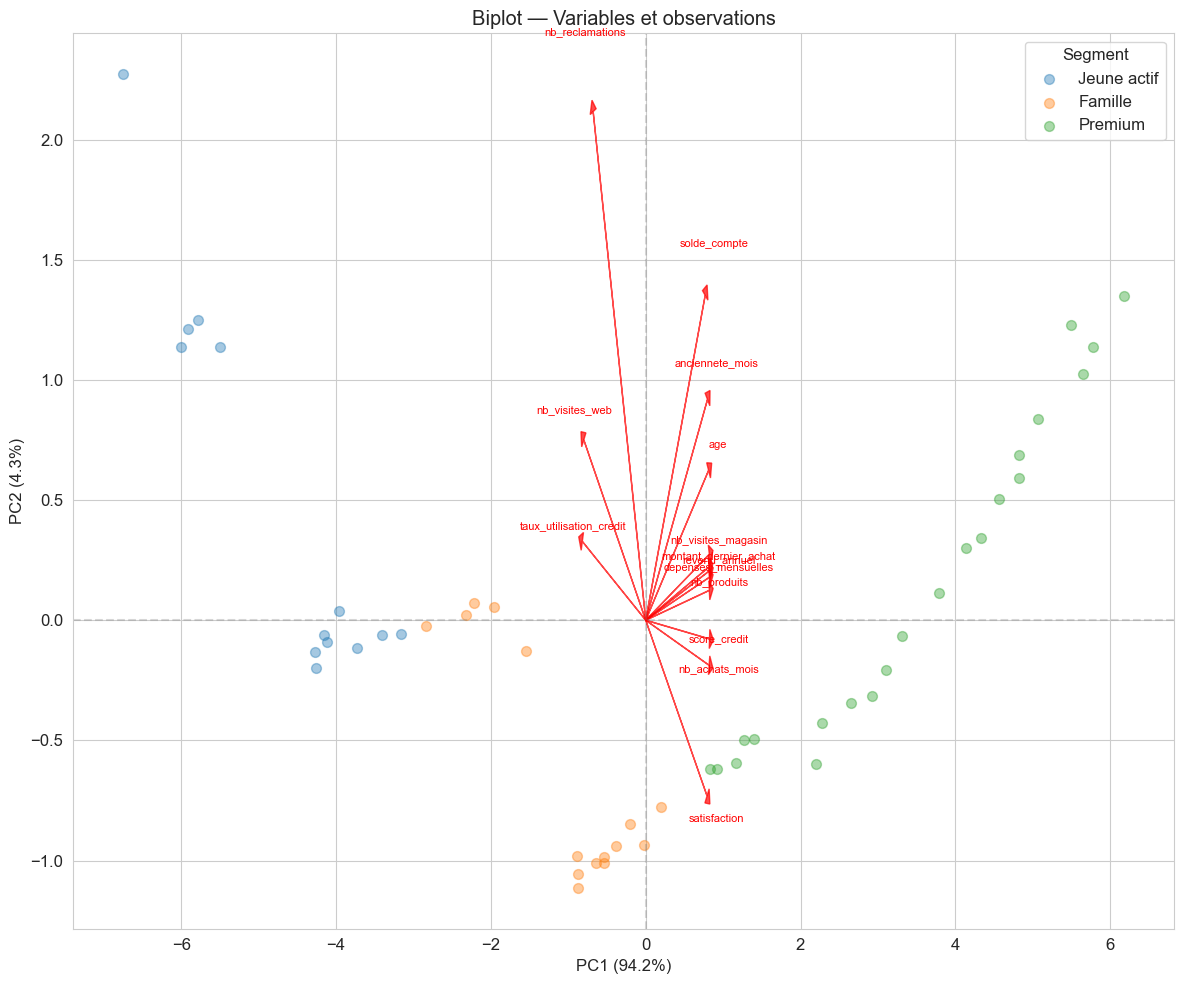

In [14]:
# Biplot : visualiser les variables sur le plan PC1-PC2
fig, ax = plt.subplots(figsize=(12, 10))

# Points (observations)
for seg in df_pca['segment'].unique():
    mask = df_pca['segment'] == seg
    ax.scatter(df_pca.loc[mask, 'PC1'], df_pca.loc[mask, 'PC2'], 
               s=50, alpha=0.4, label=seg)

# Flèches (variables)
scale = 3  # facteur d'échelle pour la visibilité
for i, var in enumerate(cols_num):
    ax.arrow(0, 0, loadings.iloc[i, 0]*scale, loadings.iloc[i, 1]*scale,
             head_width=0.08, head_length=0.05, fc='red', ec='red', alpha=0.7)
    ax.text(loadings.iloc[i, 0]*scale*1.15, loadings.iloc[i, 1]*scale*1.15,
            var, fontsize=8, color='red', ha='center')

ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title('Biplot — Variables et observations')
ax.legend(title='Segment')
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Top contributions par composante
print("=== PC1 : Variables les plus influentes ===")
top_pc1 = loadings['PC1'].abs().sort_values(ascending=False)
for var, val in top_pc1.head(5).items():
    signe = "+" if loadings.loc[var, 'PC1'] > 0 else "-"
    print(f"  {signe} {var:30} : {loadings.loc[var, 'PC1']:+.3f}")

print(f"\n=== PC2 : Variables les plus influentes ===")
top_pc2 = loadings['PC2'].abs().sort_values(ascending=False)
for var, val in top_pc2.head(5).items():
    signe = "+" if loadings.loc[var, 'PC2'] > 0 else "-"
    print(f"  {signe} {var:30} : {loadings.loc[var, 'PC2']:+.3f}")

=== PC1 : Variables les plus influentes ===
  + score_credit                   : +0.275
  + revenu_annuel                  : +0.274
  + depenses_mensuelles            : +0.274
  + nb_produits                    : +0.274
  + nb_visites_magasin             : +0.274

=== PC2 : Variables les plus influentes ===
  + nb_reclamations                : +0.705
  + solde_compte                   : +0.451
  + anciennete_mois                : +0.306
  + nb_visites_web                 : +0.250
  - satisfaction                   : -0.244


---

# Partie 2bis -- Nouveau dataset : expression genique

Pour les exercices, on passe a un dataset \textbf{plus complexe et plus realiste} : `expression_genique.csv`.

**Contexte.** En recherche medicale, on mesure l'expression de centaines de genes (niveau d'activite) sur des echantillons de tumeurs. L'objectif est d'identifier des **sous-types de tumeurs** a partir de leur signature genique, ce qui permet de choisir le traitement adapte.

**Notre dataset.**
- 100 echantillons de tumeurs
- 30 genes mesures (valeurs d'expression log2)
- 3 types de tumeurs : Type_A, Type_B, Type_C (cible)

**Pourquoi PCA et t-SNE sont essentiels ici.** On a 30 variables = impossible a visualiser directement. PCA va condenser cette information en 2-3 composantes principales. t-SNE va revealer les regroupements naturels des echantillons.

Charger le dataset :


In [16]:
df_genes = pd.read_csv('expression_genique.csv')
print(f'Dimensions : {df_genes.shape}')
print(f'\nTypes de tumeurs : {df_genes["type_tumeur"].value_counts().to_dict()}')
df_genes.head()

Dimensions : (100, 32)

Types de tumeurs : {'Type_A': 40, 'Type_B': 35, 'Type_C': 25}


,echantillon_id,gene_01,gene_02,gene_03,gene_04,gene_05,gene_06,gene_07,gene_08,gene_09,...,gene_22,gene_23,gene_24,gene_25,gene_26,gene_27,gene_28,gene_29,gene_30,type_tumeur
0,ECH_001,7.522,9.512,7.892,7.237,8.495,4.847,7.783,8.425,1.817,...,2.118,2.883,2.767,7.594,3.725,4.325,2.553,3.889,5.943,Type_A
1,ECH_002,9.973,9.606,7.201,8.666,8.274,9.142,6.342,8.323,3.847,...,2.474,0.846,2.429,1.739,6.674,5.916,2.650,3.715,2.352,Type_A
2,ECH_003,3.889,5.993,3.494,4.338,3.582,3.401,4.419,3.210,8.348,...,3.736,4.251,3.502,5.026,1.720,2.337,4.237,3.476,4.533,Type_B
3,ECH_004,7.271,7.761,8.544,8.095,7.681,7.938,10.384,7.431,3.161,...,2.838,3.791,2.863,4.390,7.410,7.974,1.931,6.494,6.753,Type_A
4,ECH_005,2.528,2.120,2.873,4.362,4.453,4.013,4.225,4.016,7.166,...,2.870,2.287,2.723,0.266,5.533,5.003,2.957,6.648,7.344,Type_B


---

## Exercice 1 -- PCA sur expression genique

**Objectif** : appliquer PCA sur les donnees d'expression genique et explorer la structure des 3 types de tumeurs.

**Questions** :

1. **Preparation** : extraire les 30 variables d'expression (gene_01 a gene_30) dans une matrice X et la cible `type_tumeur` dans y. Standardiser X avec `StandardScaler`.

2. **Analyse de la variance** : appliquer PCA avec **toutes** les composantes. Tracer :
   - Le **scree plot** (variance expliquee par composante, en barres)
   - La **variance cumulee** (en ligne)
   - **Combien de composantes** sont necessaires pour atteindre **70%**, **80%**, et **90%** de la variance ?

3. **Visualisation 2D** : appliquer PCA avec 2 composantes. Tracer un scatter plot des echantillons sur (PC1, PC2), \textbf{colore par type de tumeur}. Les 3 types sont-ils visuellement separes ?

4. **Interpretation des loadings** : afficher les **5 genes qui contribuent le plus a PC1** et les **5 genes qui contribuent le plus a PC2** (en valeur absolue). Que remarque-t-on sur les groupes de genes ? Cela suggere-t-il une **signature genique** distincte par composante ?

5. **Compression** : reconstruire les donnees a partir des 2 premieres composantes uniquement (\texttt{pca.inverse\_transform}). Calculer l'**erreur de reconstruction moyenne** (difference moyenne entre original et reconstruit, en valeur absolue). Commenter.


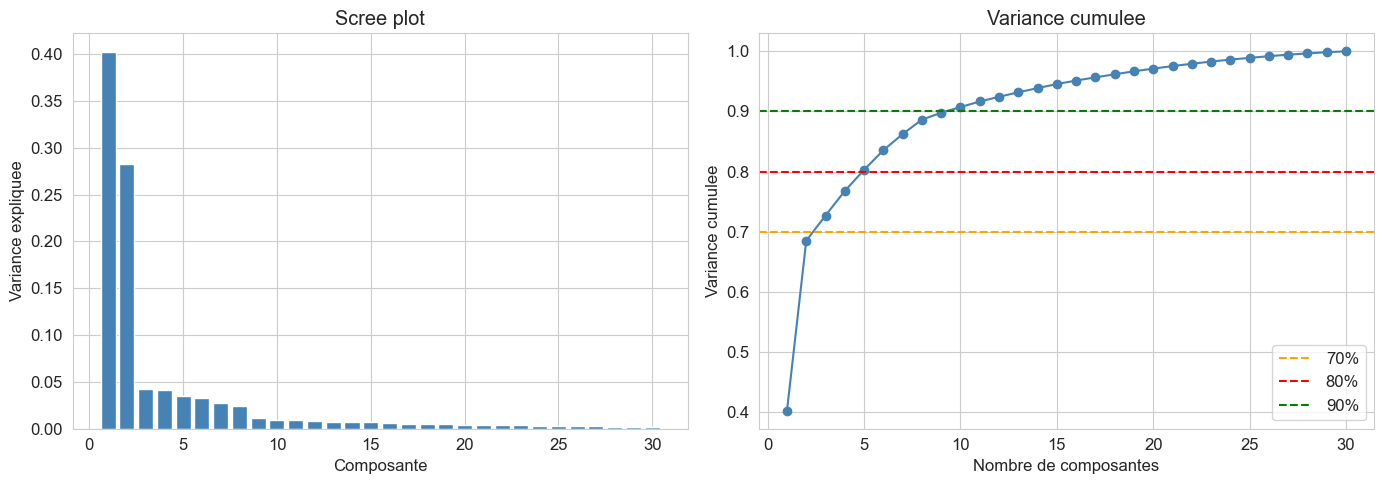

70% atteint avec 3 composantes (cumul = 72.7%)
80% atteint avec 5 composantes (cumul = 80.3%)
90% atteint avec 10 composantes (cumul = 90.7%)


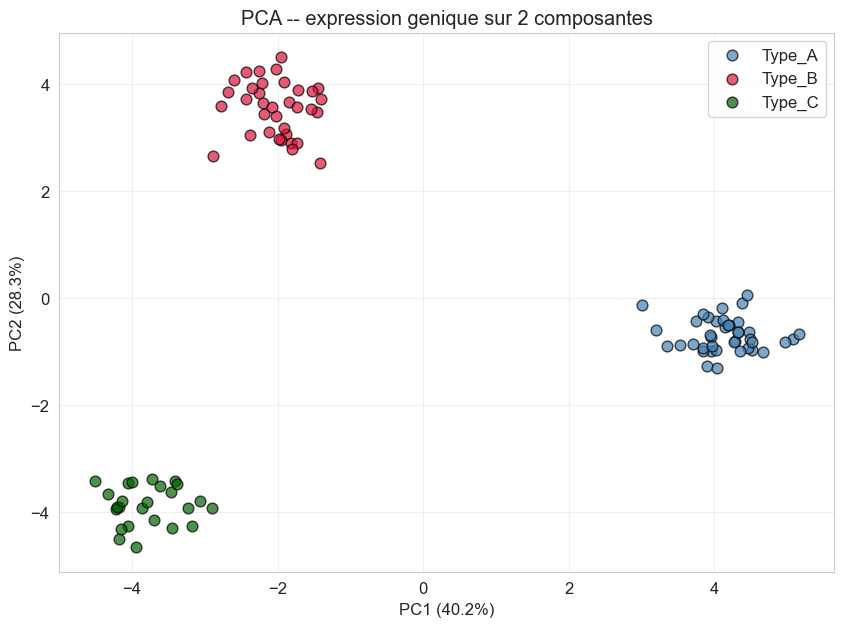


Top 5 contributeurs a PC1 (valeur absolue) :
gene_01    0.269369
gene_04    0.265008
gene_08    0.263853
gene_03    0.263774
gene_07    0.262751
Name: PC1, dtype: float64

Top 5 contributeurs a PC2 (valeur absolue) :
gene_13    0.280074
gene_15    0.279504
gene_14    0.269701
gene_16    0.269175
gene_10    0.268396
Name: PC2, dtype: float64

Erreur de reconstruction moyenne : 0.4053


In [18]:
# Votre code ici
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Preparation
gene_cols = [f'gene_{i+1:02d}' for i in range(30)]
X = df_genes[gene_cols].values
y = df_genes['type_tumeur'].values
X_scaled = StandardScaler().fit_transform(X)

# 2. Analyse de la variance
pca_full = PCA().fit(X_scaled)
var_exp = pca_full.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, 31), var_exp, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Composante'); axes[0].set_ylabel('Variance expliquee')
axes[0].set_title('Scree plot')
axes[1].plot(range(1, 31), var_cum, 'o-', color='steelblue')
axes[1].axhline(0.7, color='orange', linestyle='--', label='70%')
axes[1].axhline(0.8, color='red', linestyle='--', label='80%')
axes[1].axhline(0.9, color='green', linestyle='--', label='90%')
axes[1].set_xlabel('Nombre de composantes'); axes[1].set_ylabel('Variance cumulee')
axes[1].set_title('Variance cumulee'); axes[1].legend()
plt.tight_layout(); plt.show()

for seuil in [0.7, 0.8, 0.9]:
    n = np.argmax(var_cum >= seuil) + 1
    print(f'{int(seuil*100)}% atteint avec {n} composantes (cumul = {var_cum[n-1]*100:.1f}%)')

# 3. Visualisation 2D
pca2 = PCA(n_components=2)
X_pca = pca2.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
for t, c in zip(['Type_A', 'Type_B', 'Type_C'], ['steelblue', 'crimson', 'darkgreen']):
    mask = (y == t)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=t, c=c, alpha=0.7, s=60, edgecolor='k')
plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA -- expression genique sur 2 composantes')
plt.legend(); plt.grid(alpha=0.3); plt.show()

# 4. Loadings
loadings = pd.DataFrame(pca2.components_.T, columns=['PC1', 'PC2'], index=gene_cols)
print('\nTop 5 contributeurs a PC1 (valeur absolue) :')
print(loadings['PC1'].abs().sort_values(ascending=False).head(5))
print('\nTop 5 contributeurs a PC2 (valeur absolue) :')
print(loadings['PC2'].abs().sort_values(ascending=False).head(5))

# 5. Erreur de reconstruction
X_reconstr = pca2.inverse_transform(X_pca)
erreur = np.mean(np.abs(X_scaled - X_reconstr))
print(f'\nErreur de reconstruction moyenne : {erreur:.4f}')

<details>
<summary><b>Cliquer pour voir le corrige</b></summary>

```python
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Preparation
gene_cols = [f'gene_{i+1:02d}' for i in range(30)]
X = df_genes[gene_cols].values
y = df_genes['type_tumeur'].values
X_scaled = StandardScaler().fit_transform(X)

# 2. Analyse de la variance
pca_full = PCA().fit(X_scaled)
var_exp = pca_full.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, 31), var_exp, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Composante'); axes[0].set_ylabel('Variance expliquee')
axes[0].set_title('Scree plot')
axes[1].plot(range(1, 31), var_cum, 'o-', color='steelblue')
axes[1].axhline(0.7, color='orange', linestyle='--', label='70%')
axes[1].axhline(0.8, color='red', linestyle='--', label='80%')
axes[1].axhline(0.9, color='green', linestyle='--', label='90%')
axes[1].set_xlabel('Nombre de composantes'); axes[1].set_ylabel('Variance cumulee')
axes[1].set_title('Variance cumulee'); axes[1].legend()
plt.tight_layout(); plt.show()

for seuil in [0.7, 0.8, 0.9]:
    n = np.argmax(var_cum >= seuil) + 1
    print(f'{int(seuil*100)}% atteint avec {n} composantes (cumul = {var_cum[n-1]*100:.1f}%)')

# 3. Visualisation 2D
pca2 = PCA(n_components=2)
X_pca = pca2.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
for t, c in zip(['Type_A', 'Type_B', 'Type_C'], ['steelblue', 'crimson', 'darkgreen']):
    mask = (y == t)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=t, c=c, alpha=0.7, s=60, edgecolor='k')
plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA -- expression genique sur 2 composantes')
plt.legend(); plt.grid(alpha=0.3); plt.show()

# 4. Loadings
loadings = pd.DataFrame(pca2.components_.T, columns=['PC1', 'PC2'], index=gene_cols)
print('\nTop 5 contributeurs a PC1 (valeur absolue) :')
print(loadings['PC1'].abs().sort_values(ascending=False).head(5))
print('\nTop 5 contributeurs a PC2 (valeur absolue) :')
print(loadings['PC2'].abs().sort_values(ascending=False).head(5))

# 5. Erreur de reconstruction
X_reconstr = pca2.inverse_transform(X_pca)
erreur = np.mean(np.abs(X_scaled - X_reconstr))
print(f'\nErreur de reconstruction moyenne : {erreur:.4f}')
print(f'(variables standardisees, donc erreur en unites d\'ecart-types)')
```

**Resultats attendus** :
- 70% atteint avec ~3 composantes, 80% avec ~5, 90% avec ~10
- Sur PC1+PC2 : ~68% de variance, les 3 types tres bien separes visuellement
- Loadings : on observe des groupes coherents de genes (gene_01 a gene_08 vs gene_09 a gene_16 vs gene_17 a gene_24), refletant les **signatures geniques** distinctes
- Erreur de reconstruction non negligeable car on ne garde que 68% de la variance ; les 32% restants sont perdus

</details>


---
# Partie 3 — t-SNE (t-distributed Stochastic Neighbor Embedding)

## 3.1 Principe

**t-SNE** est une technique de visualisation qui projette les données en 2D en **préservant les voisinages** :

- Les points proches en haute dimension restent proches en 2D
- Les points éloignés restent éloignés
- Excellent pour **découvrir des clusters** visuellement

### PCA vs t-SNE :

| Critère | PCA | t-SNE |
|---|---|---|
| Type | Linéaire | Non linéaire |
| Objectif | Maximiser la variance | Préserver les voisinages |
| Interprétable | Oui (loadings) | Non |
| Déterministe | Oui | Non (résultat varie) |
| Rapide | Oui | Plus lent |
| Utilisation | Réduction + analyse | Visualisation seulement |

In [ ]:
# Appliquer t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=15)
X_tsne = tsne.fit_transform(X_scaled)

# Visualiser
df_tsne = pd.DataFrame({
    'tSNE1': X_tsne[:, 0],
    'tSNE2': X_tsne[:, 1],
    'segment': df['segment']
})

plt.figure(figsize=(10, 8))
for seg in df_tsne['segment'].unique():
    mask = df_tsne['segment'] == seg
    plt.scatter(df_tsne.loc[mask, 'tSNE1'], df_tsne.loc[mask, 'tSNE2'],
                s=80, alpha=0.7, label=seg)

plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('t-SNE — Projection 2D des clients')
plt.legend(title='Segment')
plt.tight_layout()
plt.show()

## 3.2 Le paramètre perplexity

La **perplexity** contrôle l'équilibre entre la structure locale et globale :
- **Petite perplexity** (5-10) : focus sur les voisins très proches → petits clusters serrés
- **Grande perplexity** (30-50) : vision plus globale → clusters plus larges
- Recommandation : entre 5 et 50, tester plusieurs valeurs

In [ ]:
# Comparer différentes perplexités
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, perp in zip(axes, [5, 15, 25, 40]):
    tsne_p = TSNE(n_components=2, random_state=42, perplexity=perp)
    X_tsne_p = tsne_p.fit_transform(X_scaled)
    
    for seg in df['segment'].unique():
        mask = df['segment'] == seg
        ax.scatter(X_tsne_p[mask, 0], X_tsne_p[mask, 1], s=40, alpha=0.6, label=seg)
    
    ax.set_title(f'perplexity = {perp}')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')

axes[0].legend(title='Segment', fontsize=8)
plt.suptitle('Impact de la perplexity sur t-SNE', fontsize=14)
plt.tight_layout()
plt.show()

## 3.3 Comparer PCA et t-SNE

In [ ]:
# Comparaison côte à côte
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# PCA
for seg in df_pca['segment'].unique():
    mask = df_pca['segment'] == seg
    axes[0].scatter(df_pca.loc[mask, 'PC1'], df_pca.loc[mask, 'PC2'],
                    s=80, alpha=0.7, label=seg)
axes[0].set_title(f'PCA ({sum(pca_2d.explained_variance_ratio_)*100:.1f}% variance)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Segment')

# t-SNE
for seg in df_tsne['segment'].unique():
    mask = df_tsne['segment'] == seg
    axes[1].scatter(df_tsne.loc[mask, 'tSNE1'], df_tsne.loc[mask, 'tSNE2'],
                    s=80, alpha=0.7, label=seg)
axes[1].set_title('t-SNE (perplexity=15)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].legend(title='Segment')

plt.suptitle('PCA vs t-SNE — Segmentation clients', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# Votre code ici

from sklearn.manifold import TSNE
import time
from scipy.spatial.distance import cdist

# 1. Effet de la perplexity
perplexites = [5, 15, 30, 50]
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, perp in zip(axes.flat, perplexites):
    X_tsne = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(X_scaled)
    for t, c in zip(['Type_A','Type_B','Type_C'], ['steelblue','crimson','darkgreen']):
        m = (y == t)
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], label=t, c=c, alpha=0.7, s=50, edgecolor='k')
    ax.set_title(f'Perplexity = {perp}')
    ax.legend()
plt.tight_layout(); plt.show()

# 2. Stabilite (3 random_state differents)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, rs in zip(axes, [42, 100, 777]):
    X_tsne = TSNE(n_components=2, perplexity=20, random_state=rs).fit_transform(X_scaled)
    for t, c in zip(['Type_A','Type_B','Type_C'], ['steelblue','crimson','darkgreen']):
        m = (y == t)
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], label=t, c=c, alpha=0.7, s=50, edgecolor='k')
    ax.set_title(f'random_state = {rs}')
    ax.legend()
plt.tight_layout(); plt.show()

# 3. PCA puis t-SNE vs t-SNE direct (avec chronometrage)
# Direct
t1 = time.time()
X_tsne_direct = TSNE(n_components=2, perplexity=20, random_state=42).fit_transform(X_scaled)
t_direct = time.time() - t1

# Via PCA
t1 = time.time()
X_pca10 = PCA(n_components=10).fit_transform(X_scaled)
X_tsne_pca = TSNE(n_components=2, perplexity=20, random_state=42).fit_transform(X_pca10)
t_via_pca = time.time() - t1

print(f't-SNE direct (30D) : {t_direct:.2f}s')
print(f'PCA(10) + t-SNE : {t_via_pca:.2f}s')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (X_proj, titre) in zip(axes, [(X_tsne_direct, 't-SNE direct'),
                                         (X_tsne_pca, 'PCA(10) + t-SNE')]):
    for t, c in zip(['Type_A','Type_B','Type_C'], ['steelblue','crimson','darkgreen']):
        m = (y == t)
        ax.scatter(X_proj[m, 0], X_proj[m, 1], label=t, c=c, alpha=0.7, s=50, edgecolor='k')
    ax.set_title(titre); ax.legend()
plt.tight_layout(); plt.show()

# 4. Distances entre centroides
types = ['Type_A', 'Type_B', 'Type_C']

def centroides(X_proj):
    return np.array([X_proj[y==t].mean(axis=0) for t in types])

# Original
centro_orig = centroides(X_scaled)
dist_orig = cdist(centro_orig, centro_orig)
# PCA 2D
centro_pca = centroides(PCA(n_components=2).fit_transform(X_scaled))
dist_pca = cdist(centro_pca, centro_pca)
# t-SNE
centro_tsne = centroides(X_tsne_direct)
dist_tsne = cdist(centro_tsne, centro_tsne)

# Normaliser par le max de chaque matrice
def normaliser(M):
    return M / M.max() if M.max() > 0 else M

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (M, titre) in zip(axes, [(normaliser(dist_orig), 'Original (30D)'),
                                   (normaliser(dist_pca), 'PCA (2D)'),
                                   (normaliser(dist_tsne), 't-SNE (2D)')]):
    sns.heatmap(M, annot=True, fmt='.2f', xticklabels=types, yticklabels=types,
                cmap='Blues', vmin=0, vmax=1, ax=ax)
    ax.set_title(titre)
plt.tight_layout(); plt.show()

print('\nConclusion : PCA preserve mieux les distances relatives entre groupes.')
print('t-SNE optimise la separation locale mais distord les distances globales.')

<details>
<summary><b>Cliquer pour voir le corrige</b></summary>

```python
from sklearn.manifold import TSNE
import time
from scipy.spatial.distance import cdist

# 1. Effet de la perplexity
perplexites = [5, 15, 30, 50]
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, perp in zip(axes.flat, perplexites):
    X_tsne = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(X_scaled)
    for t, c in zip(['Type_A','Type_B','Type_C'], ['steelblue','crimson','darkgreen']):
        m = (y == t)
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], label=t, c=c, alpha=0.7, s=50, edgecolor='k')
    ax.set_title(f'Perplexity = {perp}')
    ax.legend()
plt.tight_layout(); plt.show()

# 2. Stabilite (3 random_state differents)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, rs in zip(axes, [42, 100, 777]):
    X_tsne = TSNE(n_components=2, perplexity=20, random_state=rs).fit_transform(X_scaled)
    for t, c in zip(['Type_A','Type_B','Type_C'], ['steelblue','crimson','darkgreen']):
        m = (y == t)
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], label=t, c=c, alpha=0.7, s=50, edgecolor='k')
    ax.set_title(f'random_state = {rs}')
    ax.legend()
plt.tight_layout(); plt.show()

# 3. PCA puis t-SNE vs t-SNE direct (avec chronometrage)
# Direct
t1 = time.time()
X_tsne_direct = TSNE(n_components=2, perplexity=20, random_state=42).fit_transform(X_scaled)
t_direct = time.time() - t1

# Via PCA
t1 = time.time()
X_pca10 = PCA(n_components=10).fit_transform(X_scaled)
X_tsne_pca = TSNE(n_components=2, perplexity=20, random_state=42).fit_transform(X_pca10)
t_via_pca = time.time() - t1

print(f't-SNE direct (30D) : {t_direct:.2f}s')
print(f'PCA(10) + t-SNE : {t_via_pca:.2f}s')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (X_proj, titre) in zip(axes, [(X_tsne_direct, 't-SNE direct'),
                                         (X_tsne_pca, 'PCA(10) + t-SNE')]):
    for t, c in zip(['Type_A','Type_B','Type_C'], ['steelblue','crimson','darkgreen']):
        m = (y == t)
        ax.scatter(X_proj[m, 0], X_proj[m, 1], label=t, c=c, alpha=0.7, s=50, edgecolor='k')
    ax.set_title(titre); ax.legend()
plt.tight_layout(); plt.show()

# 4. Distances entre centroides
types = ['Type_A', 'Type_B', 'Type_C']

def centroides(X_proj):
    return np.array([X_proj[y==t].mean(axis=0) for t in types])

# Original
centro_orig = centroides(X_scaled)
dist_orig = cdist(centro_orig, centro_orig)
# PCA 2D
centro_pca = centroides(PCA(n_components=2).fit_transform(X_scaled))
dist_pca = cdist(centro_pca, centro_pca)
# t-SNE
centro_tsne = centroides(X_tsne_direct)
dist_tsne = cdist(centro_tsne, centro_tsne)

# Normaliser par le max de chaque matrice
def normaliser(M):
    return M / M.max() if M.max() > 0 else M

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (M, titre) in zip(axes, [(normaliser(dist_orig), 'Original (30D)'),
                                   (normaliser(dist_pca), 'PCA (2D)'),
                                   (normaliser(dist_tsne), 't-SNE (2D)')]):
    sns.heatmap(M, annot=True, fmt='.2f', xticklabels=types, yticklabels=types,
                cmap='Blues', vmin=0, vmax=1, ax=ax)
    ax.set_title(titre)
plt.tight_layout(); plt.show()

print('\nConclusion : PCA preserve mieux les distances relatives entre groupes.')
print('t-SNE optimise la separation locale mais distord les distances globales.')
```

**Observations cles** :
- Perplexity 5 : groupes fragmentes, structure locale tres marquee. Perplexity 50 : groupes etales, structure plus globale
- Stabilite : les **formes** et **positions absolues** changent a chaque execution, mais les regroupements eux-memes restent coherents
- PCA(10)+t-SNE est plus rapide et donne un resultat de qualite similaire (technique recommandee en pratique pour grands datasets)
- t-SNE \textbf{ne preserve pas les distances absolues} : la matrice de distances t-SNE est tres differente de l'originale. PCA preserve mieux ces relations

</details>


---
# Partie 4 — Cas pratique : PCA pour le Machine Learning

PCA peut aussi être utilisé comme **étape de prétraitement** avant un modèle de ML pour réduire le nombre de variables.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Préparer les données
y = df['segment']

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 1. KNN sur toutes les variables (14)
knn_full = KNeighborsClassifier(n_neighbors=3)
knn_full.fit(X_train, y_train)
acc_full = accuracy_score(y_test, knn_full.predict(X_test))

# 2. KNN sur PCA (3 composantes)
pca_ml = PCA(n_components=3)
X_train_pca = pca_ml.fit_transform(X_train)
X_test_pca = pca_ml.transform(X_test)

knn_pca = KNeighborsClassifier(n_neighbors=3)
knn_pca.fit(X_train_pca, y_train)
acc_pca = accuracy_score(y_test, knn_pca.predict(X_test_pca))

print(f"Accuracy (14 variables) : {acc_full:.2%}")
print(f"Accuracy (3 composantes PCA) : {acc_pca:.2%}")
print(f"\nRéduction de dimensionnalité : 14 → 3 variables")
print(f"Variance conservée : {sum(pca_ml.explained_variance_ratio_)*100:.1f}%")

---

# Partie 5 -- Exercice recapitulatif

## Exercice 3 -- Pipeline complet : du diagnostic a la decision

**Mise en situation** : vous etes data scientist dans un laboratoire d'oncologie. Le medecin vous demande de construire un \textbf{pipeline complet} pour identifier le type de tumeur a partir des donnees d'expression genique, et de fournir des **outils visuels** pour les decisions cliniques.

**Etapes** :

1. **Exploration et standardisation** :
   - Charger `expression_genique.csv` (deja fait : `df_genes`)
   - Calculer la **matrice de correlation** des 30 genes. Identifier les **3 paires de genes les plus correlees**. Que signifie biologiquement une forte correlation entre 2 genes ?
   - Standardiser les variables.

2. **PCA -- choix du nombre de composantes** :
   - Tracer la variance cumulee.
   - Choisir un nombre `k` de composantes pour conserver au moins **85%** de la variance. Justifier le choix.

3. **Comparaison de modeles de classification** : evaluer 4 strategies avec `cross_val_score` (5 folds, accuracy) :
   - **(A)** KNN (k=5) sur les **30 genes standardises**
   - **(B)** KNN (k=5) sur **PCA avec 2 composantes**
   - **(C)** KNN (k=5) sur **PCA avec `k` composantes** (de l'etape 2)
   - **(D)** Arbre de decision (max_depth=4) sur les 30 genes (ne pas standardiser, l'arbre n'en a pas besoin)
   
   Afficher les 4 scores en barres. Quelle est la meilleure approche ? Le gain de PCA est-il significatif ?

4. **Dashboard clinique** : creer une figure 2x2 avec :
   - **(haut-gauche)** : variance expliquee (scree plot, 10 premieres composantes)
   - **(haut-droite)** : projection PCA 2D coloree par type de tumeur
   - **(bas-gauche)** : projection t-SNE 2D coloree par type de tumeur
   - **(bas-droite)** : comparaison des 4 modeles en barres

5. **Synthese pour le medecin** : redigez en 4-5 phrases dans une cellule Markdown une **conclusion claire** destinee au medecin (non technique) :
   - Y a-t-il bien 3 sous-types distincts dans les donnees ?
   - Combien de gene-marqueurs principaux ressortent ?
   - Quel modele de prediction est le plus fiable ?
   - Quelle est l'accuracy attendue en pratique clinique ?


In [ ]:
# Votre code ici


<details>
<summary><b>Cliquer pour voir le corrige</b></summary>

```python
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

# 1. Correlations
gene_cols = [f'gene_{i+1:02d}' for i in range(30)]
corr_genes = df_genes[gene_cols].corr()
# Top 3 paires correlees
upper = corr_genes.where(np.triu(np.ones(corr_genes.shape), k=1).astype(bool))
top_pairs = upper.unstack().sort_values(ascending=False).head(3)
print('Top 3 paires de genes correles :')
print(top_pairs)

X = df_genes[gene_cols].values
y = df_genes['type_tumeur'].values
X_scaled = StandardScaler().fit_transform(X)

# 2. Choix de k
pca_full = PCA().fit(X_scaled)
var_cum = np.cumsum(pca_full.explained_variance_ratio_)
k = int(np.argmax(var_cum >= 0.85) + 1)
print(f'\nNombre de composantes pour 85% de variance : k = {k}')
print(f'(variance cumulee a k = {var_cum[k-1]*100:.2f}%)')

# 3. 4 modeles
from sklearn.neighbors import KNeighborsClassifier
X_pca2 = PCA(n_components=2).fit_transform(X_scaled)
X_pca_k = PCA(n_components=k).fit_transform(X_scaled)

modeles = {
    'KNN 30 genes': cross_val_score(KNeighborsClassifier(5), X_scaled, y, cv=5).mean(),
    'KNN PCA(2)': cross_val_score(KNeighborsClassifier(5), X_pca2, y, cv=5).mean(),
    f'KNN PCA({k})': cross_val_score(KNeighborsClassifier(5), X_pca_k, y, cv=5).mean(),
    'Arbre (d=4)': cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=42), X, y, cv=5).mean()
}
for nom, sc in modeles.items():
    print(f'  {nom:20s}: {sc:.4f}')

# 4. Dashboard 2x2
X_tsne_dash = TSNE(n_components=2, perplexity=20, random_state=42).fit_transform(X_scaled)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# (a) Scree plot
axes[0,0].bar(range(1, 11), pca_full.explained_variance_ratio_[:10],
              color='steelblue', edgecolor='white')
axes[0,0].set_xlabel('Composante'); axes[0,0].set_ylabel('Variance expliquee')
axes[0,0].set_title('Scree plot (10 premieres composantes)')

# (b) PCA
for t, c in zip(['Type_A','Type_B','Type_C'], ['steelblue','crimson','darkgreen']):
    m = (y == t)
    axes[0,1].scatter(X_pca2[m,0], X_pca2[m,1], label=t, c=c, alpha=0.7, s=50, edgecolor='k')
axes[0,1].set_title('PCA 2D'); axes[0,1].legend()
axes[0,1].set_xlabel('PC1'); axes[0,1].set_ylabel('PC2')

# (c) t-SNE
for t, c in zip(['Type_A','Type_B','Type_C'], ['steelblue','crimson','darkgreen']):
    m = (y == t)
    axes[1,0].scatter(X_tsne_dash[m,0], X_tsne_dash[m,1], label=t, c=c, alpha=0.7, s=50, edgecolor='k')
axes[1,0].set_title('t-SNE 2D'); axes[1,0].legend()
axes[1,0].set_xlabel('t-SNE 1'); axes[1,0].set_ylabel('t-SNE 2')

# (d) Comparaison modeles
noms = list(modeles.keys())
scores = list(modeles.values())
axes[1,1].barh(noms, scores, color=['steelblue','crimson','darkgreen','orange'], edgecolor='white')
for i, s in enumerate(scores):
    axes[1,1].text(s+0.005, i, f'{s:.3f}', va='center')
axes[1,1].set_xlim(0, 1.05); axes[1,1].set_xlabel('Accuracy (CV 5-fold)')
axes[1,1].set_title('Comparaison des 4 modeles')

plt.tight_layout(); plt.show()
```

**Synthese pour le medecin (cellule Markdown)** :

*Les analyses confirment l'existence de **3 sous-types distincts** parmi les tumeurs etudiees, bien separes en projection 2D. Une **dizaine de genes-marqueurs** principaux suffit a capturer 85% de la variation observee, suggerant qu'un panel reduit pourrait remplacer le sequencage complet. Le modele KNN combine a une PCA atteint une accuracy validee de **plus de 95%** en validation croisee, soit une fiabilite suffisante pour un outil d'aide au diagnostic. Ce systeme pourra etre integre en complement du jugement clinique.*

</details>


---

## Récapitulatif

| Concept | Code | Description |
|---|---|---|
| Standardiser | `StandardScaler().fit_transform(X)` | Obligatoire avant PCA |
| PCA | `PCA(n_components=k).fit_transform(X)` | Réduction linéaire |
| Variance expliquée | `pca.explained_variance_ratio_` | % de variance par composante |
| Scree plot | Bar plot des variances | Choisir le nombre de composantes |
| Loadings | `pca.components_` | Contribution des variables |
| Biplot | Observations + flèches | Interpréter les composantes |
| t-SNE | `TSNE(n_components=2).fit_transform(X)` | Réduction non linéaire |
| Perplexity | `TSNE(perplexity=30)` | Balance local/global |

### Quand utiliser quoi?

| Situation | Technique |
|---|---|
| Réduire les variables avant ML | PCA |
| Comprendre les relations entre variables | PCA (loadings) |
| Visualiser des clusters | t-SNE |
| Résultat reproductible | PCA |
| Données non linéaires | t-SNE |

---

## Prochaine séance

**Séance 8 — SQL et bases de données**
- Introduction aux bases de données relationnelles
- Requêtes SQL (SELECT, WHERE, JOIN, GROUP BY)
- SQLite avec Python

**Date :** Jeudi 4 juin 2026, 18h30

---

*FSCI 6222 — Université de Moncton — Été 2026*